In [135]:
# Library
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb
from pathlib import Path
import os

import warnings
warnings.filterwarnings('ignore')
print(os.getcwd())

/home/yahia/gci_world-2026/notebooks


In [136]:
# Read the file 
client = pd.read_csv('../data/raw/Client.csv')
record = pd.read_csv('../data/raw/Record.csv')

In [137]:
# Dispaly data content of the (Client) dataset
print(f"Number of columns and rows: {client.shape}")
print(f"Show the first 5 columns: {client.head()}")

Number of columns and rows: (100000, 50)
Show the first 5 columns:    uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls       totmou  \
0         2         1        U        A        N      1652   4228.00000   
1         1         1        N       EA        N     14654  26400.00000   
2         1         1        Y        C        N      7903  24385.05333   
3         1         1        Y        B        N      1502   3065.00000   
4         1         1        Y        A        N      4485  14028.00000   

    totrev   adjrev    adjmou  ...  forgntvl  ethnic  kid0_2  kid3_5  kid6_10  \
0  1504.62  1453.44   4085.00  ...       0.0       N       U       U        U   
1  2851.68  2833.88  26367.00  ...       0.0       Z       U       U        U   
2  2155.91  1934.47  24303.05  ...       0.0       N       U       Y        U   
3  2000.90  1941.81   3035.00  ...       0.0       U       Y       U        U   
4  2181.12  2166.48  13965.00  ...       0.0       I       U       U        U

In [138]:
# Dispaly data content of the (record) dataste
print(f"Number of columns and row: {record.shape}")
print(f"Show the first 5 columns: {record.head()}")

Number of columns and row: (100000, 51)
Show the first 5 columns:    rev_Mean  mou_Mean  totmrc_Mean  da_Mean  ovrmou_Mean  ovrrev_Mean  \
0   23.9975    219.25       22.500   0.2475         0.00          0.0   
1   57.4925    482.75       37.425   0.2475        22.75          9.1   
2   16.9900     10.25       16.990   0.0000         0.00          0.0   
3   38.0000      7.50       38.000   0.0000         0.00          0.0   
4   55.2300    570.50       71.980   0.0000         0.00          0.0   

   vceovr_Mean  datovr_Mean  roam_Mean  change_mou  ...  mou_opkv_Mean  \
0          0.0          0.0        0.0     -157.25  ...      55.220000   
1          9.1          0.0        0.0      532.25  ...     169.343333   
2          0.0          0.0        0.0       -4.25  ...       0.233333   
3          0.0          0.0        0.0       -1.50  ...       5.450000   
4          0.0          0.0        0.0       38.50  ...     218.086667   

   mou_opkd_Mean  drop_blk_Mean  attempt_Mean  com

In [139]:
# Porporation of missing values of the file (cilent and record)
missing_value_client = client.isnull().sum() / client.shape[0]
print(f"Missing values in the file client:\n {missing_value_client.sort_values(ascending=False).head(10)}")

missing_value_record = record.isnull().sum() / record.shape[0]
print(f"Missing values in the record file: \n {missing_value_record.sort_values(ascending=False).head(10)}")

Missing values in the file client:
 numbcars      0.49366
dwllsize      0.38308
HHstatin      0.37923
ownrent       0.33706
dwlltype      0.31909
lor           0.30190
income        0.25436
adults        0.23019
infobase      0.22079
hnd_webcap    0.10189
dtype: float64
Missing values in the record file: 
 change_mou     0.00891
change_rev     0.00891
rev_Mean       0.00357
totmrc_Mean    0.00357
mou_Mean       0.00357
da_Mean        0.00357
ovrmou_Mean    0.00357
vceovr_Mean    0.00357
ovrrev_Mean    0.00357
roam_Mean      0.00357
dtype: float64


In [140]:
# Cleaning up the data in the client file
client_missing = client.isnull().mean()
cols_to_fix = client_missing[client_missing > 0].index.tolist()

for col in cols_to_fix:
    client[f"{col}_is_missing"] = client[col].isnull().astype(int)

    if pd.api.types.is_numeric_dtype(client[col]):
        client[col] = client[col].fillna(client[col].median())
    else:
        client[col] = client[col].fillna('Unknown')

print("Remaing misssing values in client: ", client.isnull().sum().sum())


Remaing misssing values in client:  0


In [141]:
# Cleaning up the data in the record file 
# Compensating for lsst values usnig the mean
from sklearn.impute import SimpleImputer

record_missing = record.isnull().mean()
cols_low_missing = record_missing[(record_missing > 0) & (record_missing < 0.01)].index.tolist()
print(f"The columns to be replaced: {cols_low_missing}")

imputer = SimpleImputer(strategy='median')
record[cols_low_missing] = imputer.fit_transform(record[cols_low_missing])

print("The missing values in the record file have been successfully replaced")

The columns to be replaced: ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev']
The missing values in the record file have been successfully replaced


In [142]:
# Handling null values 
cols = ['hnd_webcap','prizm_social_one' ,'avg6rev', 'avg6qty', 'avg6mou', 'rv', 'forgntvl', 'ethnic', 'kid0_2']
print(client[cols].dtypes)
client[cols].describe()

rows = ['lor', 'income', 'adults']

for row in rows:
    client[row] = client[row].fillna(client[row].median())

print(client[['lor', 'income', 'adults']])

hnd_webcap              str
prizm_social_one        str
avg6rev             float64
avg6qty             float64
avg6mou             float64
rv                  float64
forgntvl            float64
ethnic                  str
kid0_2                  str
dtype: object
        lor  income  adults
0      15.0     4.0     1.0
1       1.0     5.0     1.0
2       7.0     5.0     2.0
3       6.0     6.0     4.0
4       5.0     6.0     1.0
...     ...     ...     ...
99995  15.0     4.0     5.0
99996   9.0     7.0     3.0
99997   5.0     9.0     1.0
99998   5.0     6.0     2.0
99999   2.0     4.0     2.0

[100000 rows x 3 columns]


In [143]:
# Porporation of missing values of the file (cilent and record)
missing_value_client = client.isnull().sum() / client.shape[0]
print(f"Missing values in the file client:\n {missing_value_client.sort_values(ascending=False).head(10)}")

missing_value_record = record.isnull().sum() / record.shape[0]
print(f"Missing values in the record file: \n {missing_value_record.sort_values(ascending=False).head(10)}")

Missing values in the file client:
 uniqsubs    0.0
actvsubs    0.0
new_cell    0.0
crclscod    0.0
asl_flag    0.0
totcalls    0.0
totmou      0.0
totrev      0.0
adjrev      0.0
adjmou      0.0
dtype: float64
Missing values in the record file: 
 rev_Mean       0.0
mou_Mean       0.0
totmrc_Mean    0.0
da_Mean        0.0
ovrmou_Mean    0.0
ovrrev_Mean    0.0
vceovr_Mean    0.0
datovr_Mean    0.0
roam_Mean      0.0
change_mou     0.0
dtype: float64


In [144]:
print("CLIENT COLUMNS")
print(client.columns.tolist())

print("\nRECORD COLUMNS")
print(record.columns.tolist())

print("Client")
print(client.columns.duplicated().sum())
print("record")
print(record.columns.duplicated().sum())

CLIENT COLUMNS
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID', 'avg6mou_is_missing', 'avg6qty_is_missing', 'avg6rev_is_missing', 'prizm_social_one_is_missing', 'area_is_missing', 'dualband_is_missing', 'refurb_new_is_missing', 'hnd_price_is_missing', 'phones_is_missing', 'models_is_missing', 'hnd_webcap_is_missing', 'truck_is_missing', 'rv_is_missing', 'ownrent_is_missing', 'lor_is_missing', 'dwlltype_is_missing', 'marital_is_missing', 'adults_is_missing', 'infobase_is_missing', 'inco

2 Churn Analysis

In [145]:
# Check target and identifier 
print("Churn in client", 'churn' in client.columns)
print("churn in record", 'churn' in record.columns)

print("Duplicate IDs in client: ", client['Customer_ID'].duplicated().sum())
print("Duplicate IDs in record: ", record['Customer_ID'].duplicated().sum())

Churn in client False
churn in record True
Duplicate IDs in client:  0
Duplicate IDs in record:  0


In [146]:
# Merge the two file cilent and record
df = client.merge(record,
                    on='Customer_ID',
                    how='inner',
                    validate='one_to_one')

print('Final dataset: ', df.shape)
print(df["churn"].value_counts())

Final dataset:  (100000, 132)
churn
0    50438
1    49562
Name: count, dtype: int64


In [147]:
# Inspect merged dataset structure and data types
df.info()

#Numeric and categorical columns #
print("Numeric columns: ", df.select_dtypes(include=np.number).shape[1])
print("Non_numeric columns: ", df.select_dtypes(exclude=np.number).shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 132 entries, uniqsubs to months
dtypes: float64(69), int64(42), str(21)
memory usage: 100.7 MB
Numeric columns:  111
Non_numeric columns:  21


In [148]:
# Delete fixed columns
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
print(f"Constant columns to drop: {constant_cols}")

Constant columns to drop: []


In [149]:
features = [
    'mou_Mean',
    'rev_Mean',
    'custcare_Mean',
    'drop_vce_Mean',
    'blck_vce_Mean',
    'months',
    'eqpdays',
    'change_mou',
    'change_rev'
]
comparison = df.groupby('churn')[features].agg(
    ['mean', 'median']
)
display(comparison)

mou_Mean          rev_Mean           custcare_Mean         \
             mean median       mean    median          mean median   
churn                                                                
0      542.790083  379.5  59.194214  48.79125      1.982599    0.0   
1      482.674631  332.0  58.161561  47.73750      1.595688    0.0   

      drop_vce_Mean        blck_vce_Mean            months            eqpdays  \
               mean median          mean median       mean median        mean   
churn                                                                           
0          6.090553    3.0      4.118370    1.0  18.633074   16.0  363.280503   
1          5.817222    3.0      3.925776    1.0  19.038457   17.0  421.089524   

             change_mou        change_rev           
      median       mean median       mean   median  
churn                                               
0      310.0  -5.348090  -3.25  -1.405570 -0.31375  
1      366.0 -22.533162  -8.75  -0.617074 -0.31500

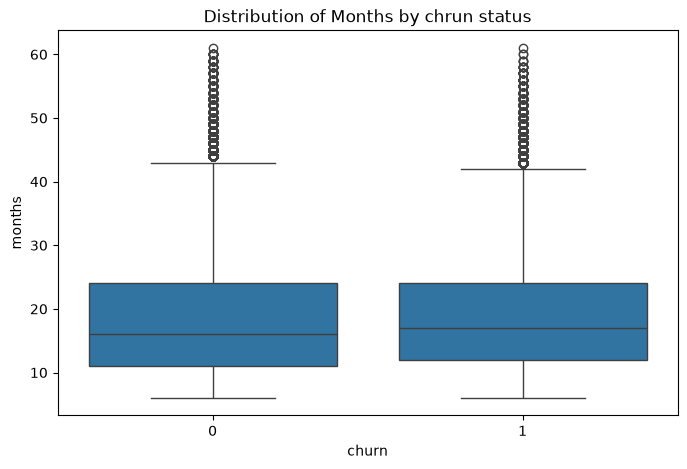

In [150]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='churn', y='months', data=df)
plt.title('Distribution of Months by chrun status')
plt.show()

Top 20 Features by Effect Size (Cohen's d):


,Feature,Cohens_d
0,eqpdays,0.226837
1,hnd_price,0.206457
2,totmrc_Mean,0.137332
3,hnd_webcap_is_missing,0.129485
4,mou_Mean,0.114844
5,mou_cvce_Mean,0.104227
6,complete_Mean,0.103623
7,comp_vce_Mean,0.103289
8,avg3mou,0.099217
9,mou_opkv_Mean,0.097912


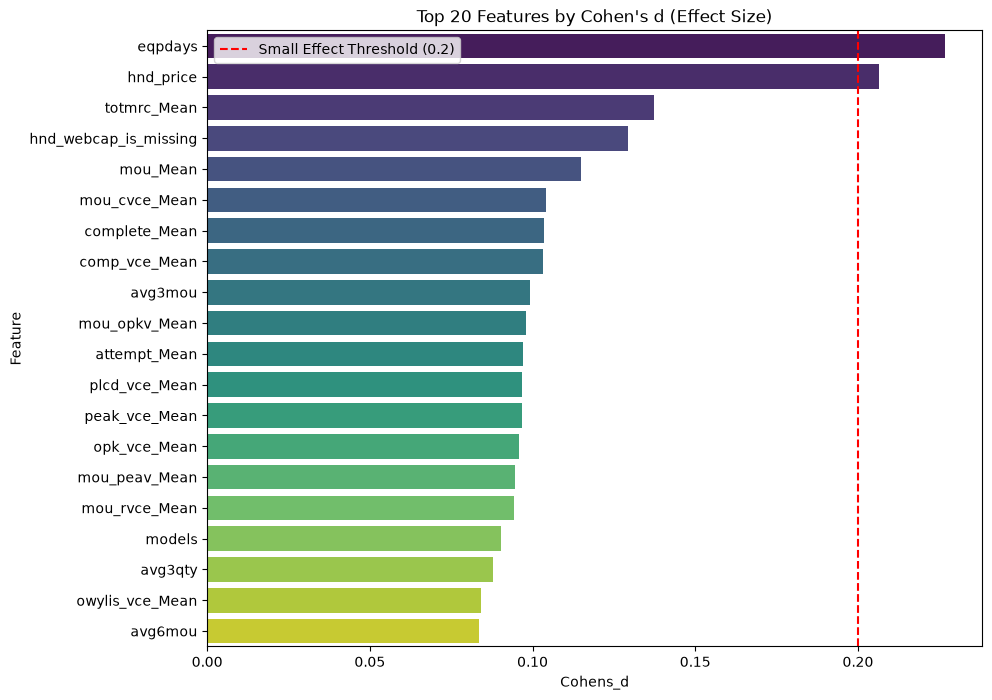

In [151]:
# Now cell : Calculate cohen's d for all numeric featuresand sort them
from pandas.api.types import is_numeric_dtype

# 1. Extract all numeric columns except 'churn' and 'Customer_ID
numeric_cols = [col for col in df.columns if is_numeric_dtype(df[col]) and col not in ['churn', 'Customer_ID']]

# 2. Function to calculate cohen's d
def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    var1, var2 = group1.var(), group2.var()
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    if pooled_std == 0: return 0 
    return abs((group1.mean() - group2.mean()) / pooled_std)

effect_sizes = {}
for col in numeric_cols:
    effect_sizes[col] = cohens_d(df[df['churn']==0][col], df[df['churn']==1][col])

effect_df = pd.DataFrame(list(effect_sizes.items()), columns=['Feature', 'Cohens_d'])
effect_df = effect_df.sort_values(by='Cohens_d', ascending=False).reset_index(drop=True)

# 3. Print top 20 features 
print("Top 20 Features by Effect Size (Cohen's d):")
display(effect_df.head(20))

# 6. Plto shwoing the strongest features 
plt.figure(figsize=(10, 8))
sns.barplot(x='Cohens_d', y='Feature', data=effect_df.head(20), palette='viridis')
plt.title('Top 20 Features by Cohen\'s d (Effect Size)')
plt.axvline(x=0.2, color='red', linestyle='--', label='Small Effect Threshold (0.2)')
plt.legend()
plt.show()

In [152]:
from scipy.stats import ttest_ind
churn_0 = df[df['churn'] == 0]['mou_Mean']
churn_1 = df[df['churn'] == 1]['mou_Mean']
stat, p = ttest_ind(churn_0, churn_1)
print(f'f-value: {p}')

f-value: 1.4669173609371142e-73


Top 20 features by absolute correlation with churn:


,correlation_with_churn
eqpdays,0.112693
hnd_price,-0.102680
totmrc_Mean,-0.068503
hnd_webcap_is_missing,0.064605
mou_Mean,-0.057326
mou_cvce_Mean,-0.052042
complete_Mean,-0.051740
comp_vce_Mean,-0.051574
avg3mou,-0.049546
mou_opkv_Mean,-0.048896


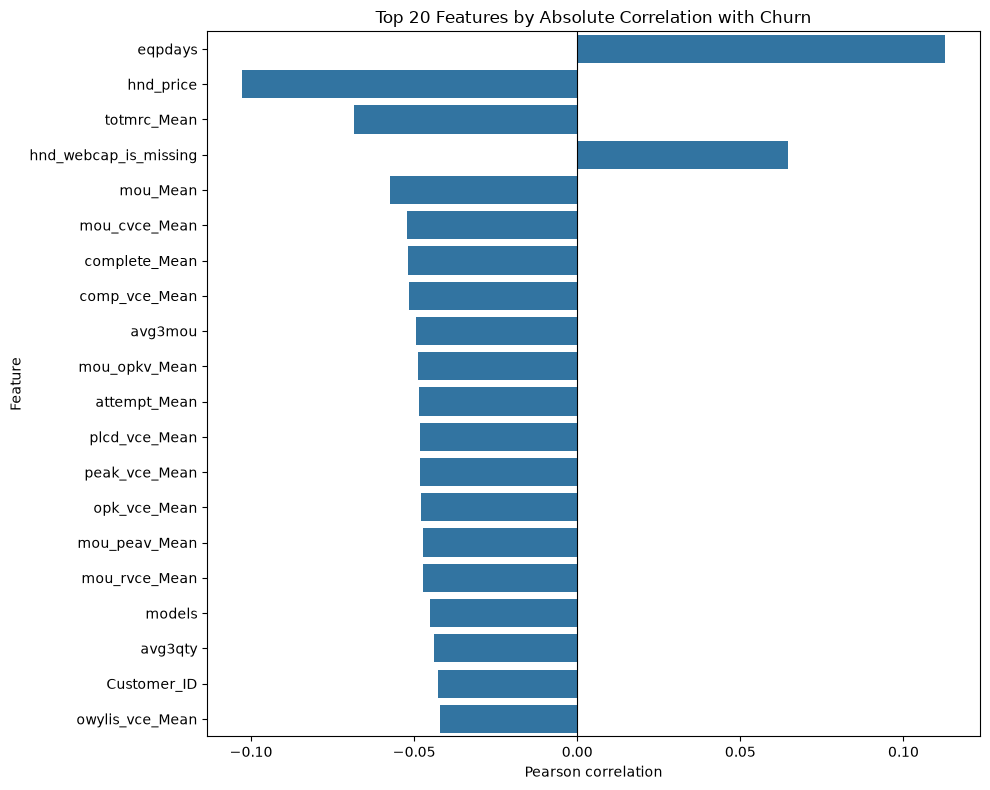

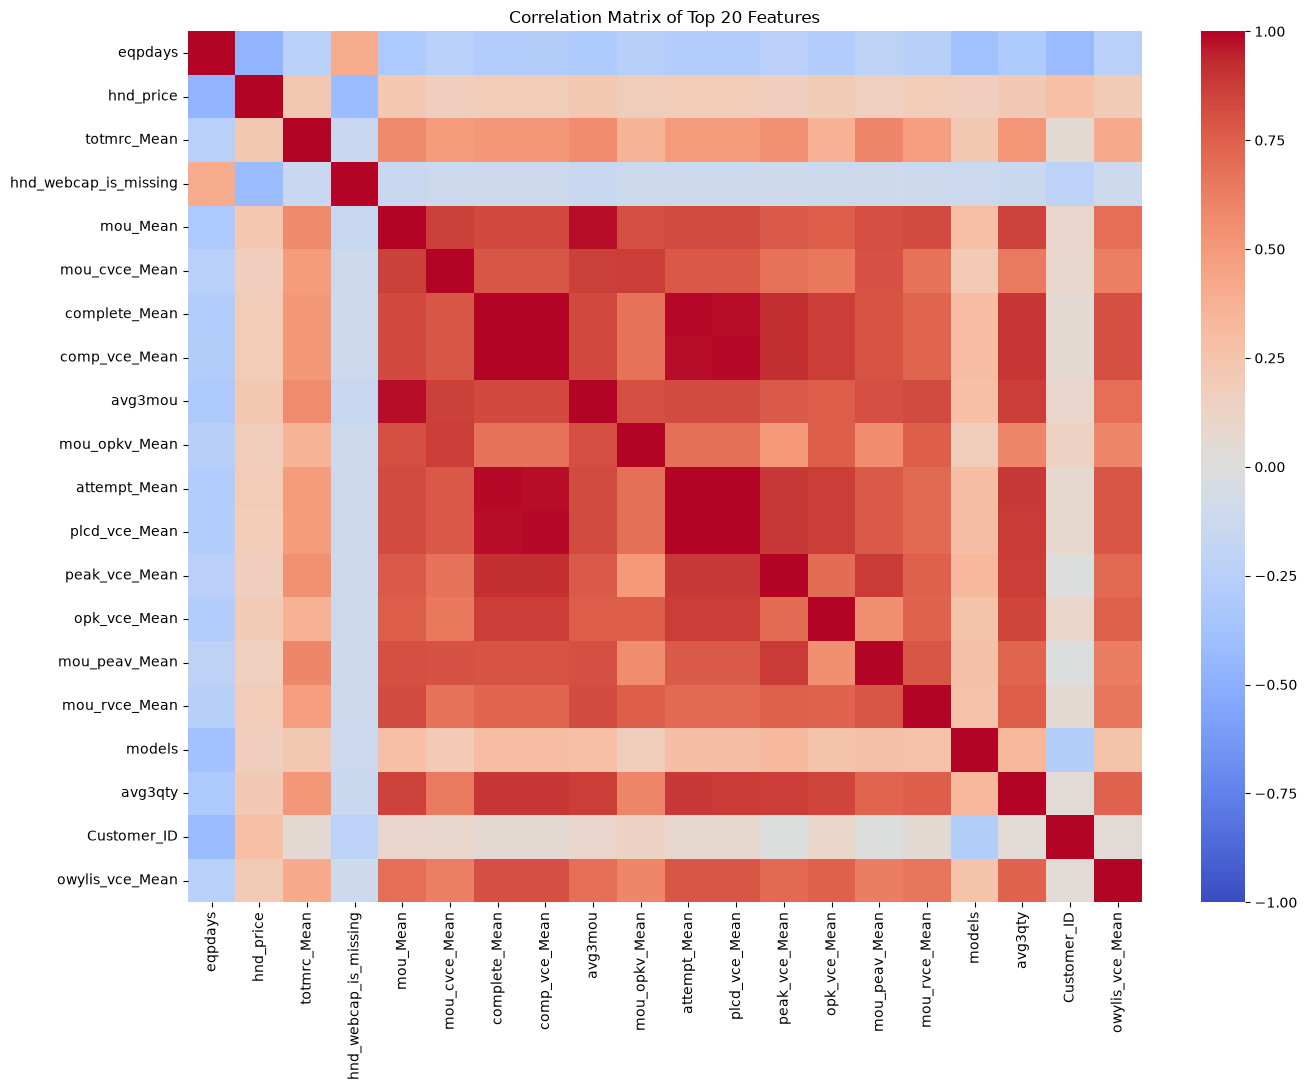

In [153]:
# Correlation with the target: rank by absolute value so negative
# and positive relationships are both included.
numeric_df = df.select_dtypes(include=[np.number])
corr_with_target = numeric_df.corr()["churn"].drop("churn")
top_corr = corr_with_target.reindex(
    corr_with_target.abs().sort_values(ascending=False).head(20).index
)

print("Top 20 features by absolute correlation with churn:")
display(top_corr.to_frame("correlation_with_churn"))

plt.figure(figsize=(10, 8))
sns.barplot(
    x=top_corr.values,
    y=top_corr.index,
    orient="h"
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 20 Features by Absolute Correlation with Churn")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Correlation matrix among the selected 20 features
top_feature_names = top_corr.index.tolist()
top_feature_corr = numeric_df[top_feature_names].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(
    top_feature_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix of Top 20 Features")
plt.tight_layout()
plt.show()


In [154]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

X = df.drop(columns=['churn'])
y = df['churn']

cat_cols = X.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in cat_cols:
    X[col] = le.fit_transform(X[col].astype(str))

print(X.dtypes)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_}).sort_values(by='Importance', ascending=False)

print(importance.head(20))

uniqsubs           int64
actvsubs           int64
new_cell           int64
crclscod           int64
asl_flag           int64
                  ...   
attempt_Mean     float64
complete_Mean    float64
callfwdv_Mean    float64
callwait_Mean    float64
months             int64
Length: 131, dtype: object
           Feature  Importance
48         eqpdays    0.031954
91      change_mou    0.024713
49     Customer_ID    0.023127
130         months    0.022328
92      change_rev    0.019875
83        mou_Mean    0.019646
8           adjrev    0.019168
7           totrev    0.019135
11          avgrev    0.019057
13          avgqty    0.018886
12          avgmou    0.018317
82        rev_Mean    0.017837
5         totcalls    0.017694
10          adjqty    0.017443
9           adjmou    0.017373
14         avg3mou    0.017371
6           totmou    0.017231
110  mou_cvce_Mean    0.016905
119  mou_peav_Mean    0.016720
17         avg6mou    0.016561


In [155]:
corr_matrix = df.select_dtypes(include=[np.number]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
print(f"Highly correlated columns to drop: {to_drop}")

Highly correlated columns to drop: ['totmou', 'adjrev', 'adjmou', 'adjqty', 'avg3qty', 'avg6mou', 'avg6qty', 'avg6qty_is_missing', 'avg6rev_is_missing', 'refurb_new_is_missing', 'phones_is_missing', 'models_is_missing', 'rv_is_missing', 'marital_is_missing', 'infobase_is_missing', 'income_is_missing', 'forgntvl_is_missing', 'ethnic_is_missing', 'kid0_2_is_missing', 'kid3_5_is_missing', 'kid6_10_is_missing', 'kid11_15_is_missing', 'kid16_17_is_missing', 'creditcd_is_missing', 'eqpdays_is_missing', 'rev_Mean', 'mou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'opk_dat_Mean', 'mou_opkd_Mean', 'attempt_Mean', 'complete_Mean']


In [156]:
# Clean up and select the correct columns 
df_clean = df.drop(columns=constant_cols + to_drop)
df_clean.to_csv('../data/processed/cleaned_data_eda.csv', index=False)

In [157]:
print(df_clean.shape)

(100000, 93)
